In [1]:
%pip install pyarrow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 6.5 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
#session et jeux de données
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.functions import vector_to_array

BASE = os.path.expanduser("~/bosch-bigdata")
P = f"{BASE}/data/parquet"
os.makedirs(f"{BASE}/modeles", exist_ok=True)
os.makedirs(f"{BASE}/figures", exist_ok=True)

spark = (SparkSession.builder
         .appName("BoschModelisation")
         .master("local[*]")
         .config("spark.driver.memory", "5g")
         .config("spark.sql.shuffle.partitions", "64")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

final = spark.read.parquet(f"{P}/final")
toutes_variables = [c for c in final.columns if c not in ("Id", "Response", "split")]
train = final.filter("split = 'train'").drop("split")
valid = final.filter("split = 'valid'").drop("split")
test  = final.filter("split = 'test'").drop("split")

# Échantillon 1 : sous-échantillonnage (tous les défauts + 10 % des conformes)
train.sampleBy("Response", {0: 0.10, 1: 1.0}, seed=42) \
     .write.mode("overwrite").parquet(f"{P}/train_sous")
# Échantillon 2 : tirage simple de taille comparable (garde le déséquilibre naturel)
train.sample(fraction=0.105, seed=42) \
     .write.mode("overwrite").parquet(f"{P}/train_simple")

train_sous = spark.read.parquet(f"{P}/train_sous")
train_simple = spark.read.parquet(f"{P}/train_simple")
for nom, df in [("Sous-échantillonné", train_sous), ("Tirage simple", train_simple)]:
    r = df.agg(F.count("*").alias("n"), F.sum("Response").alias("d")).first()
    print(f"{nom:20s} : {r['n']:,} pièces | {r['d']:,} défauts | {100 * r['d'] / r['n']:.2f} %")
print("Variables disponibles :", len(toutes_variables))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/14 17:21:12 WARN Utils: Your hostname, Vamoussa, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/14 17:21:12 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/14 17:21:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

Sous-échantillonné   : 87,459 pièces | 4,839 défauts | 5.53 %
Tirage simple        : 87,209 pièces | 486 défauts | 0.56 %
Variables disponibles : 827


In [4]:
#fonctions d’évaluation
def probas(modele, df):
    return (modele.transform(df)
            .select("Response", vector_to_array("probability")[1].alias("p"))
            .toPandas())

def confusion(y, p, seuil):
    pred = p >= seuil
    tp = int(np.sum(pred & (y == 1))); fp = int(np.sum(pred & (y == 0)))
    fn = int(np.sum(~pred & (y == 1))); tn = int(np.sum(~pred & (y == 0)))
    return tp, fp, fn, tn

def mcc(tp, fp, fn, tn):
    den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return (tp * tn - fp * fn) / den if den else 0.0

def auc_pr(y, p):
    ordre = np.argsort(-p)
    y_tri = y[ordre]
    vp_cumul = np.cumsum(y_tri)
    precision = vp_cumul / np.arange(1, len(y) + 1)
    return float(np.sum(precision * y_tri) / y.sum())

def evaluer(nom, modele, df, duree):
    pr = probas(modele, df)
    y, p = pr["Response"].to_numpy(), pr["p"].to_numpy()
    seuils = np.round(np.linspace(0.01, 0.99, 99), 2)
    courbe = pd.DataFrame({"seuil": seuils,
                           "mcc": [mcc(*confusion(y, p, s)) for s in seuils]})
    s_opt = float(courbe.loc[courbe["mcc"].idxmax(), "seuil"])
    tp, fp, fn, tn = confusion(y, p, s_opt)
    precision = tp / (tp + fp) if tp + fp else 0.0
    rappel = tp / (tp + fn)
    f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else 0.0
    res = {"modele": nom, "seuil": s_opt,
           "exactitude_%": round(100 * (tp + tn) / len(y), 2),
           "precision": round(precision, 3), "rappel": round(rappel, 3),
           "f1": round(f1, 3), "auc_pr": round(auc_pr(y, p), 3),
           "mcc": round(mcc(tp, fp, fn, tn), 3),
           "temps_s": round(duree), "TP": tp, "FP": fp, "FN": fn, "TN": tn}
    return res, courbe, y, p

In [5]:
#sélection des variables (environ 5 à 10 minutes)
assembleur_tout = VectorAssembler(inputCols=toutes_variables, outputCol="features", handleInvalid="keep")
rf_sel = RandomForestClassifier(labelCol="Response", featuresCol="features",
                                numTrees=60, maxDepth=10, seed=42)
debut = time.time()
modele_sel = Pipeline(stages=[assembleur_tout, rf_sel]).fit(train_sous)
print(f"Durée : {time.time() - debut:.0f} s")

imp = pd.Series(modele_sel.stages[-1].featureImportances.toArray(),
                index=toutes_variables).sort_values(ascending=False)
selection = imp.head(150).index.tolist()
json.dump(selection, open(f"{BASE}/modeles/variables_selectionnees.json", "w"))

def famille(v):
    if v.startswith(("visite_S", "ligne_L")) or v in ("nb_stations", "premiere_station", "derniere_station"):
        return "Parcours"
    if v in ("t_debut", "t_fin", "duree", "periode", "ecart_prec", "ecart_suiv",
             "diff_id_prec", "diff_id_suiv", "nb_meme_debut"):
        return "Temps"
    if v in ("nb_mesures", "mesure_min", "mesure_max", "mesure_moy"):
        return "Résumé"
    if v.endswith("_idx"):
        return "Catégorielle"
    return "Mesure brute"

print(f"Importance cumulée des 150 variables retenues : {imp.head(150).sum():.1%}")
print(pd.Series([famille(v) for v in selection]).value_counts().to_string())
imp.head(20)

Durée : 76 s
Importance cumulée des 150 variables retenues : 80.5%
Mesure brute    131
Temps             8
Parcours          6
Résumé            4
Catégorielle      1


diff_id_suiv        0.080073
L3_S32_F3854_idx    0.028985
L3_S32_F3850        0.023204
L3_S33_F3865        0.020423
L3_S33_F3869        0.019623
L3_S33_F3873        0.015511
L3_S29_F3455        0.015220
L3_S33_F3861        0.015028
L3_S30_F3749        0.014788
L3_S30_F3544        0.014435
L1_S24_F1846        0.014365
L3_S29_F3449        0.014315
L3_S30_F3514        0.014044
L3_S33_F3871        0.011751
L3_S33_F3857        0.011375
L3_S30_F3524        0.010667
visite_S32          0.009680
L3_S29_F3458        0.009588
L3_S30_F3724        0.009331
L3_S29_F3412        0.008725
dtype: float64

In [6]:
#section 3.3, gestion du déséquilibre (environ 20 à 30 minutes au total)
assembleur = VectorAssembler(inputCols=selection, outputCol="features", handleInvalid="keep")

def gbt(poids=None):
    params = dict(labelCol="Response", featuresCol="features",
                  maxDepth=6, maxIter=60, stepSize=0.1, seed=42)
    if poids:
        params["weightCol"] = poids
    return GBTClassifier(**params)

r = train_simple.agg(F.sum("Response").alias("pos"), F.count("*").alias("n")).first()
ratio = (r["n"] - r["pos"]) / r["pos"]
train_pond = train_simple.withColumn("poids", F.when(F.col("Response") == 1, ratio).otherwise(1.0))

valid_sel = valid.select("Response", *selection)
strategies = {
    "Aucun traitement":     (train_simple, gbt()),
    "Pondération":          (train_pond,   gbt("poids")),
    "Sous-échantillonnage": (train_sous,   gbt()),
}

resultats_deseq = []
for nom, (df, algo) in strategies.items():
    debut = time.time()
    m = Pipeline(stages=[assembleur, algo]).fit(df)
    res, _, _, _ = evaluer(nom, m, valid_sel, time.time() - debut)
    resultats_deseq.append(res)
    print(f"{nom} terminé : MCC = {res['mcc']}")

tab_deseq = pd.DataFrame(resultats_deseq)
tab_deseq.to_csv(f"{BASE}/export/resultats_desequilibre.csv", index=False)
tab_deseq[["modele", "mcc", "rappel", "precision", "auc_pr", "seuil", "temps_s"]]

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

Aucun traitement terminé : MCC = 0.217


Pondération terminé : MCC = 0.147


[Stage 2215:========================================>             (12 + 4) / 16]

Sous-échantillonnage terminé : MCC = 0.277


,modele,mcc,rappel,precision,auc_pr,seuil,temps_s
0,Aucun traitement,0.217,0.078,0.611,0.115,0.67,53
1,Pondération,0.147,0.319,0.077,0.079,0.65,58
2,Sous-échantillonnage,0.277,0.108,0.716,0.174,0.89,61


In [ ]:
#Partie B : comparaison des modèles et réglage

Régression logistique terminé : MCC = 0.163


Forêt aléatoire terminé : MCC = 0.271


GBT terminé : MCC = 0.277


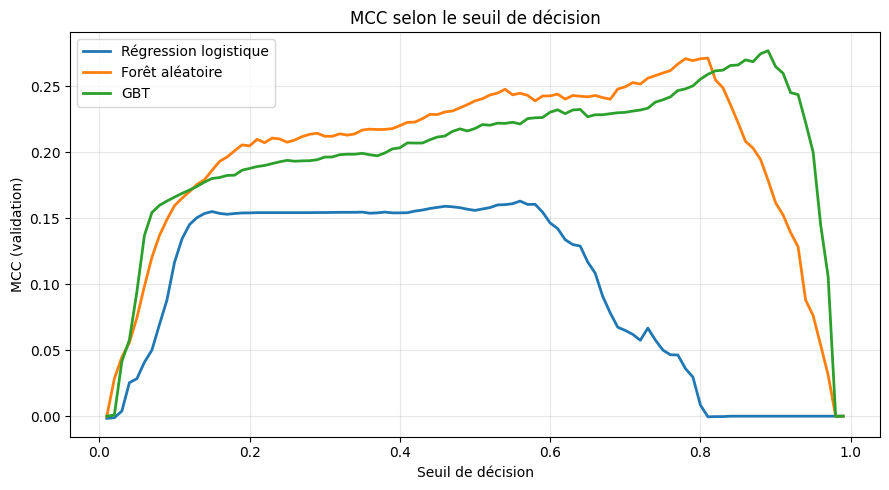

,modele,exactitude_%,mcc,rappel,precision,f1,auc_pr,seuil,temps_s
0,Naïf (tout conforme),99.42,0.000,0.000,0.000,0.000,0.006,NaN,0
1,Régression logistique,99.19,0.163,0.136,0.204,0.164,0.043,0.56,13
2,Forêt aléatoire,99.46,0.271,0.092,0.810,0.164,0.182,0.81,100
3,GBT,99.46,0.277,0.108,0.716,0.188,0.174,0.89,68


In [7]:
#section 3.2, comparaison des modèles (environ 5 minutes)
from pyspark.ml.feature import StandardScaler

n_valid = valid.count()
d_valid = valid.agg(F.sum("Response")).first()[0]
resultats_modeles = [{"modele": "Naïf (tout conforme)", "seuil": None,
    "exactitude_%": round(100 * (n_valid - d_valid) / n_valid, 2),
    "precision": 0.0, "rappel": 0.0, "f1": 0.0,
    "auc_pr": round(d_valid / n_valid, 3), "mcc": 0.0, "temps_s": 0,
    "TP": 0, "FP": 0, "FN": d_valid, "TN": n_valid - d_valid}]

modeles = {
    "Régression logistique": [assembleur,
        StandardScaler(inputCol="features", outputCol="features_std"),
        LogisticRegression(labelCol="Response", featuresCol="features_std",
                           maxIter=100, regParam=0.01)],
    "Forêt aléatoire": [assembleur,
        RandomForestClassifier(labelCol="Response", featuresCol="features",
                               numTrees=150, maxDepth=12, seed=42)],
    "GBT": [assembleur, gbt()],
}

courbes = {}
for nom, etapes in modeles.items():
    debut = time.time()
    m = Pipeline(stages=etapes).fit(train_sous)
    res, courbe, _, _ = evaluer(nom, m, valid_sel, time.time() - debut)
    resultats_modeles.append(res); courbes[nom] = courbe
    print(f"{nom} terminé : MCC = {res['mcc']}")

tab_modeles = pd.DataFrame(resultats_modeles)
tab_modeles.to_csv(f"{BASE}/export/resultats_modeles.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for nom, c in courbes.items():
    ax.plot(c["seuil"], c["mcc"], label=nom, linewidth=2)
ax.set_xlabel("Seuil de décision"); ax.set_ylabel("MCC (validation)")
ax.set_title("MCC selon le seuil de décision"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{BASE}/figures/fig_3_3_mcc_seuil.png", dpi=150); plt.show()

tab_modeles[["modele", "exactitude_%", "mcc", "rappel", "precision", "f1", "auc_pr", "seuil", "temps_s"]]

In [13]:
#quelle proportion de pièces conformes garder ? (environ 10 minutes)
resultats_frac = []
for frac in [0.05, 0.10, 0.20, 0.40]:
    chemin = f"{P}/train_sous_{int(frac * 100)}"
    (train.select("Response", *selection)
          .sampleBy("Response", {0: frac, 1: 1.0}, seed=42)
          .write.mode("overwrite").parquet(chemin))
    df = spark.read.parquet(chemin)
    n = df.count()
    debut = time.time()
    m = Pipeline(stages=[assembleur, gbt()]).fit(df)
    res, _, _, _ = evaluer(f"{int(frac * 100)} % des conformes", m, valid_sel, time.time() - debut)
    res["pieces"] = n
    resultats_frac.append(res)
    print(f"{frac:.0%} : {n:,} pièces, MCC = {res['mcc']}")

tab_frac = pd.DataFrame(resultats_frac)
tab_frac.to_csv(f"{BASE}/export/resultats_fraction.csv", index=False)
meilleure_frac = int(tab_frac.loc[tab_frac["mcc"].idxmax(), "modele"].split(" ")[0])
print("Proportion retenue :", meilleure_frac, "%")
tab_frac[["modele", "pieces", "mcc", "rappel", "precision", "seuil", "temps_s"]]

5% : 46,376 pièces, MCC = 0.253


10% : 87,459 pièces, MCC = 0.271


20% : 169,815 pièces, MCC = 0.298


[Stage 25359:=======================================>             (12 + 4) / 16]

40% : 335,040 pièces, MCC = 0.301
Proportion retenue : 40 %


,modele,pieces,mcc,rappel,precision,seuil,temps_s
0,5 % des conformes,46376,0.253,0.091,0.715,0.94,34
1,10 % des conformes,87459,0.271,0.090,0.829,0.93,44
2,20 % des conformes,169815,0.298,0.107,0.833,0.86,58
3,40 % des conformes,335040,0.301,0.116,0.788,0.64,108


In [11]:
#section 3.4, réglage des hyperparamètres du GBT (environ 15 à 25 minutes)
train_opt = spark.read.parquet(f"{P}/train_sous_{meilleure_frac}").cache()
train_opt.count()

grille = [(p, it, lr) for p in (4, 6, 8) for (it, lr) in ((60, 0.1), (150, 0.05))]
resultats_grille = []
for profondeur, iterations, pas in grille:
    algo = GBTClassifier(labelCol="Response", featuresCol="features", maxDepth=profondeur,
                         maxIter=iterations, stepSize=pas, subsamplingRate=0.8, seed=42)
    debut = time.time()
    m = Pipeline(stages=[assembleur, algo]).fit(train_opt)
    res, _, _, _ = evaluer(f"prof={profondeur}, iter={iterations}, pas={pas}", m, valid_sel, time.time() - debut)
    res.update(profondeur=profondeur, iterations=iterations, pas=pas)
    resultats_grille.append(res)
    print(res["modele"], "→ MCC =", res["mcc"])

tab_grille = pd.DataFrame(resultats_grille).sort_values("mcc", ascending=False)
tab_grille.to_csv(f"{BASE}/export/resultats_grille.csv", index=False)
best = tab_grille.iloc[0]
params = {"fraction": meilleure_frac, "maxDepth": int(best["profondeur"]),
          "maxIter": int(best["iterations"]), "stepSize": float(best["pas"]),
          "seuil": float(best["seuil"])}
json.dump(params, open(f"{BASE}/modeles/meilleurs_parametres.json", "w"))
print("Meilleure configuration :", params)
tab_grille[["modele", "mcc", "rappel", "precision", "auc_pr", "seuil", "temps_s"]]

prof=4, iter=60, pas=0.1 → MCC = 0.281


prof=4, iter=150, pas=0.05 → MCC = 0.282


prof=6, iter=60, pas=0.1 → MCC = 0.293


prof=6, iter=150, pas=0.05 → MCC = 0.301


prof=8, iter=60, pas=0.1 → MCC = 0.279


prof=8, iter=150, pas=0.05 → MCC = 0.286
Meilleure configuration : {'fraction': 40, 'maxDepth': 6, 'maxIter': 150, 'stepSize': 0.05, 'seuil': 0.69}


,modele,mcc,rappel,precision,auc_pr,seuil,temps_s
3,"prof=6, iter=150, pas=0.05",0.301,0.114,0.801,0.192,0.69,284
2,"prof=6, iter=60, pas=0.1",0.293,0.115,0.752,0.187,0.65,102
5,"prof=8, iter=150, pas=0.05",0.286,0.109,0.757,0.187,0.79,538
1,"prof=4, iter=150, pas=0.05",0.282,0.116,0.692,0.180,0.50,162
0,"prof=4, iter=60, pas=0.1",0.281,0.102,0.778,0.176,0.55,68
4,"prof=8, iter=60, pas=0.1",0.279,0.102,0.766,0.170,0.83,182


In [14]:
#dépendance aux variables « pièce suivante » (environ 3 minutes)
sans_suiv = [v for v in selection if not v.endswith("_suiv")]
print(f"Variables retirées : {len(selection) - len(sans_suiv)}")
assembleur_ss = VectorAssembler(inputCols=sans_suiv, outputCol="features", handleInvalid="keep")
algo = GBTClassifier(labelCol="Response", featuresCol="features", maxDepth=params["maxDepth"],
                     maxIter=params["maxIter"], stepSize=params["stepSize"],
                     subsamplingRate=0.8, seed=42)
debut = time.time()
m = Pipeline(stages=[assembleur_ss, algo]).fit(train_opt)
res_ss, _, _, _ = evaluer("Sans variables _suiv", m, valid_sel, time.time() - debut)
print(f"MCC avec  : {best['mcc']}")
print(f"MCC sans  : {res_ss['mcc']}")

Variables retirées : 2


[Stage 27164:=================================================>   (15 + 1) / 16]

MCC avec  : 0.301
MCC sans  : 0.234


In [ ]:
#Partie C : évaluation finale et analyses complémentaires

In [15]:
#section 3.5, évaluation unique sur le jeu de test (environ 10 minutes)
def metriques(y, p, s):
    tp, fp, fn, tn = confusion(y, p, s)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rap = tp / (tp + fn)
    return {"seuil": s, "exactitude_%": round(100 * (tp + tn) / len(y), 2),
            "precision": round(prec, 3), "rappel": round(rap, 3),
            "f1": round(2 * prec * rap / (prec + rap), 3) if prec + rap else 0.0,
            "auc_pr": round(auc_pr(y, p), 3), "mcc": round(mcc(tp, fp, fn, tn), 3),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

def gbt_final():
    return GBTClassifier(labelCol="Response", featuresCol="features",
                         maxDepth=params["maxDepth"], maxIter=params["maxIter"],
                         stepSize=params["stepSize"], subsamplingRate=0.8, seed=42)

test_sel = test.select("Id", "Response", *selection)

modele_final = Pipeline(stages=[assembleur, gbt_final()]).fit(train_opt)
modele_final.write().overwrite().save(f"{BASE}/modeles/gbt_final")
pred_test = (modele_final.transform(test_sel)
             .select("Id", "Response", vector_to_array("probability")[1].alias("p")).toPandas())

modele_ss = Pipeline(stages=[assembleur_ss, gbt_final()]).fit(train_opt)
p_ss = (modele_ss.transform(test_sel)
        .select("Id", vector_to_array("probability")[1].alias("p_ss")).toPandas())
pred_test = pred_test.merge(p_ss, on="Id")

y_t = pred_test["Response"].to_numpy()
tab_test = pd.DataFrame([
    {"modele": "GBT final (toutes variables)", **metriques(y_t, pred_test["p"].to_numpy(), params["seuil"])},
    {"modele": "GBT sans variables _suiv", **metriques(y_t, pred_test["p_ss"].to_numpy(), res_ss["seuil"])},
])
tab_test.to_csv(f"{BASE}/export/resultats_test.csv", index=False)

pred_test["prediction"] = (pred_test["p"] >= params["seuil"]).astype(int)
pred_test.to_csv(f"{BASE}/export/predictions_test.csv", index=False)
tab_test

26/10/14 19:23:28 ERROR Utils: Uncaught exception in thread executor-heartbeater
java.lang.NullPointerException: Cannot invoke "java.util.concurrent.ConcurrentHashMap.isEmpty()" because the return value of "org.apache.spark.sql.util.PartitionKeyedAccumulator.byPartition()" is null
	at org.apache.spark.sql.util.PartitionKeyedAccumulator.isZero(PartitionKeyedAccumulator.scala:51)
	at org.apache.spark.executor.Executor.$anonfun$reportHeartBeat$2(Executor.scala:1536)
	at org.apache.spark.executor.Executor.$anonfun$reportHeartBeat$2$adapted(Executor.scala:1536)
	at scala.collection.immutable.Vector.filterImpl(Vector.scala:166)
	at scala.collection.immutable.Vector.filterImpl(Vector.scala:116)
	at scala.collection.StrictOptimizedIterableOps.filterNot(StrictOptimizedIterableOps.scala:220)
	at scala.collection.StrictOptimizedIterableOps.filterNot$(StrictOptimizedIterableOps.scala:220)
	at scala.collection.immutable.Vector.filterNot(Vector.scala:116)
	at org.apache.spark.executor.Executor.$anon

,modele,seuil,exactitude_%,precision,rappel,f1,auc_pr,mcc,TP,FP,FN,TN
0,GBT final (toutes variables),0.69,99.47,0.712,0.115,0.197,0.197,0.284,116,47,897,176258
1,GBT sans variables _suiv,0.23,99.32,0.306,0.153,0.204,0.114,0.213,155,351,858,175954


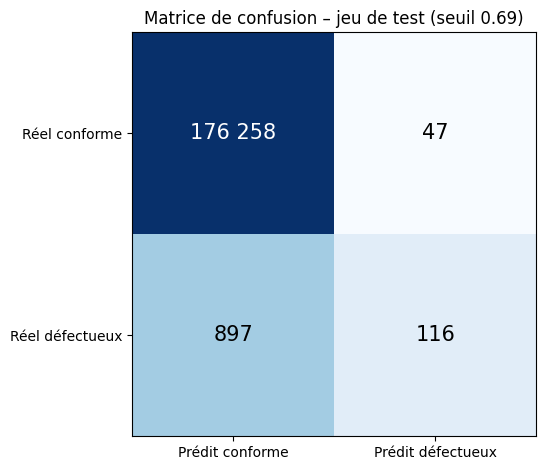

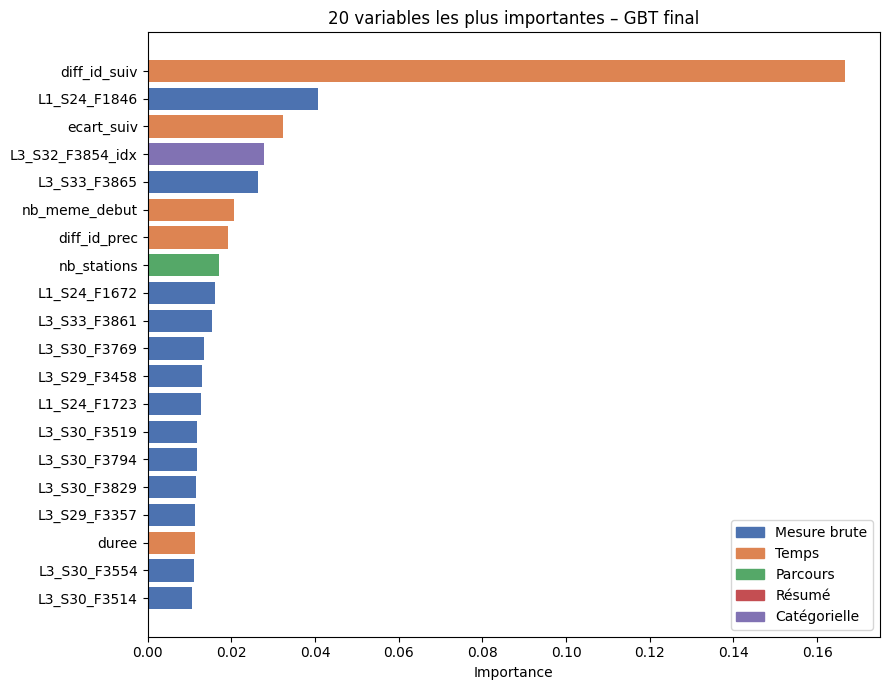

In [21]:
#matrice de confusion et importance des variables
import re
from matplotlib.patches import Patch
r = tab_test.iloc[0]
mat = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
fig, ax = plt.subplots(figsize=(6, 4.8))
ax.imshow(np.log10(mat + 1), cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{mat[i, j]:,}".replace(",", " "), ha="center", va="center", fontsize=15,
                color="white" if np.log10(mat[i, j] + 1) > 3.5 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Prédit conforme", "Prédit défectueux"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Réel conforme", "Réel défectueux"])
ax.set_title(f"Matrice de confusion – jeu de test (seuil {params['seuil']})")
plt.tight_layout(); plt.savefig(f"{BASE}/figures/fig_3_4_confusion.png", dpi=150); plt.show()

imp_final = pd.DataFrame({"variable": selection,
                          "importance": modele_final.stages[-1].featureImportances.toArray()})
imp_final["famille"] = imp_final["variable"].map(famille)
imp_final["station"] = imp_final["variable"].str.extract(r"S(\d+)")[0].map(lambda s: f"S{s}" if pd.notna(s) else "Aucune")
imp_final = imp_final.sort_values("importance", ascending=False)
imp_final.to_csv(f"{BASE}/export/importance_variables.csv", index=False)

couleurs = {"Mesure brute": "#4C72B0", "Temps": "#DD8452", "Parcours": "#55A868",
            "Résumé": "#C44E52", "Catégorielle": "#8172B3"}
top = imp_final.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["variable"], top["importance"], color=top["famille"].map(couleurs))
ax.legend(handles=[Patch(color=c, label=f) for f, c in couleurs.items()], loc="lower right")
ax.set_xlabel("Importance"); ax.set_title("20 variables les plus importantes – GBT final")
plt.tight_layout(); plt.savefig(f"{BASE}/figures/fig_3_5_importance.png", dpi=150); plt.show()

In [17]:
#analyse des erreurs
voulues = ["nb_stations", "nb_mesures", "duree", "visite_S32", "diff_id_suiv"]
cols_info = [c for c in voulues if c in test.columns]
info = test.select("Id", *cols_info).toPandas().replace(-999, np.nan)
d = pred_test.merge(info, on="Id")
d["groupe"] = np.select(
    [(d.Response == 1) & (d.prediction == 1), (d.Response == 1) & (d.prediction == 0),
     (d.Response == 0) & (d.prediction == 1)],
    ["Défaut détecté (VP)", "Défaut manqué (FN)", "Fausse alerte (FP)"],
    "Conforme bien classé (VN)")
erreurs = d.groupby("groupe").agg(pieces=("Id", "count"), proba_moy=("p", "mean"),
                                  **{f"{c}_moy": (c, "mean") for c in cols_info}).round(3)
erreurs.to_csv(f"{BASE}/export/analyse_erreurs.csv")
erreurs

,pieces,proba_moy,nb_stations_moy,nb_mesures_moy,duree_moy,visite_S32_moy,diff_id_suiv_moy
groupe,,,,,,,
Conforme bien classé (VN),176258,0.023,12.149,182.074,10.723,0.020,-602.464
Défaut détecté (VP),116,0.884,9.905,184.328,22.125,0.750,14126.681
Défaut manqué (FN),897,0.096,11.915,181.555,12.393,0.076,-12367.874
Fausse alerte (FP),47,0.824,11.404,174.128,11.799,0.915,-177448.851


k =  3 : silhouette = 0.317
k =  4 : silhouette = 0.374
k =  5 : silhouette = 0.371


k =  6 : silhouette = 0.284
k =  8 : silhouette = 0.333


k = 10 : silhouette = 0.358
k = 12 : silhouette = 0.354


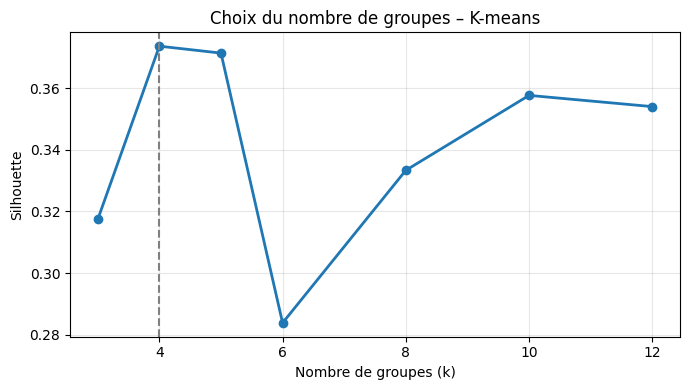

k retenu : 4


,groupe,pieces,defauts,taux_defaut_%,stations_typiques
1,1,267738,1955,0.73,"24, 26, 29, 30, 33, 34, 37"
0,0,241527,1316,0.54,"12, 13, 15, 17, 18, 20, 29, 30, 33, 34, 37"
2,2,378194,2026,0.54,"0, 1, 2, 5, 7, 8, 29, 30, 33, 34, 36, 37"
3,3,296288,1582,0.53,"0, 1, 3, 4, 6, 8, 29, 30, 33, 34, 35, 37"


In [18]:
#section 3.6, K-means sur les parcours (environ 5 minutes)
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
train_opt.unpersist()

parcours = spark.read.parquet(f"{P}/feat_parcours").join(final.select("Id", "Response"), "Id")
cols_visite = sorted([c for c in parcours.columns if c.startswith("visite_S")], key=lambda c: int(c[8:]))
vec_km = (VectorAssembler(inputCols=cols_visite, outputCol="features")
          .transform(parcours.fillna(0, subset=cols_visite)).select("Id", "Response", "features"))
ech_km = vec_km.sample(0.15, seed=42).cache()

evaluateur = ClusteringEvaluator(featuresCol="features")
sil = {}
for k in [3, 4, 5, 6, 8, 10, 12]:
    sil[k] = evaluateur.evaluate(KMeans(k=k, seed=42).fit(ech_km).transform(ech_km))
    print(f"k = {k:2d} : silhouette = {sil[k]:.3f}")
k_choisi = max(sil, key=sil.get)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(sil), list(sil.values()), marker="o", linewidth=2)
ax.axvline(k_choisi, color="grey", linestyle="--")
ax.set_xlabel("Nombre de groupes (k)"); ax.set_ylabel("Silhouette"); ax.grid(alpha=0.3)
ax.set_title("Choix du nombre de groupes – K-means")
plt.tight_layout(); plt.savefig(f"{BASE}/figures/fig_3_6_silhouette.png", dpi=150); plt.show()

km = KMeans(k=k_choisi, seed=42).fit(vec_km)
groupes = km.transform(vec_km).select("Id", "Response", F.col("prediction").alias("groupe"))
resume_km = (groupes.groupBy("groupe")
             .agg(F.count("*").alias("pieces"), F.sum("Response").alias("defauts"))
             .withColumn("taux_defaut_%", F.round(100 * F.col("defauts") / F.col("pieces"), 2))
             .orderBy("groupe").toPandas())
centres = km.clusterCenters()
resume_km["stations_typiques"] = [", ".join(c[8:] for c, v in zip(cols_visite, centres[g]) if v > 0.5)
                                  for g in resume_km["groupe"]]
resume_km.to_csv(f"{BASE}/export/kmeans_groupes.csv", index=False)
groupes.toPandas().to_csv(f"{BASE}/export/kmeans_pieces.csv", index=False)
ech_km.unpersist()
print("k retenu :", k_choisi)
resume_km.sort_values("taux_defaut_%", ascending=False)

In [22]:
#section 3.6, FP-Growth, les combinaisons de stations associées aux défauts (environ 3 minutes)
from pyspark.ml.fpm import FPGrowth

mat = parcours.select("Response", *[F.coalesce(F.col(c), F.lit(0)).cast("byte").alias(c)
                                    for c in items_utiles]).toPandas()
Y = mat["Response"].to_numpy()
X = mat[items_utiles].to_numpy().astype(bool)
idx = {c.replace("visite_", ""): i for i, c in enumerate(items_utiles)}

fpg2 = FPGrowth(itemsCol="items", minSupport=0.02).fit(defauts)
cands = fpg2.freqItemsets.filter(F.size("items") <= 3).toPandas()
print("Combinaisons candidates :", len(cands))

lignes = []
for items, f_def in zip(cands["items"], cands["freq"]):
    m = X[:, [idx[i] for i in items]].all(axis=1)
    n, d = int(m.sum()), int(Y[m].sum())
    lignes.append({"combinaison": " + ".join(sorted(items, key=lambda s: int(s[1:]))),
                   "taille": len(items), "part_des_defauts_%": round(100 * f_def / n_def, 1),
                   "pieces": n, "taux_defaut_%": round(100 * d / n, 2),
                   "lift": round((d / n) / taux_global, 2)})
regles = (pd.DataFrame(lignes).query("pieces >= 1000")
          .sort_values("lift", ascending=False))
regles.to_csv(f"{BASE}/export/regles_fpgrowth.csv", index=False)
del mat, X
regles.head(15)

Combinaisons candidates : 1136


,combinaison,taille,part_des_defauts_%,pieces,taux_defaut_%,lift
902,S24 + S26 + S32,3,3.2,2600,8.50,14.63
901,S24 + S32 + S36,3,2.2,1767,8.43,14.51
900,S24 + S32,2,3.9,3503,7.71,13.26
898,S26 + S32 + S36,3,2.7,2544,7.43,12.78
897,S26 + S32,2,5.1,4980,7.07,12.16
899,S26 + S32 + S35,3,2.4,2411,6.76,11.63
854,S32 + S36,2,8.6,12511,4.75,8.17
847,S32,1,16.1,24543,4.51,7.75
858,S32 + S35,2,7.4,11849,4.32,7.44
889,S4 + S32 + S36,3,2.3,3700,4.32,7.44
